# Image Forensic Analyzer for Digital Tampering Detection
### Multimedia Forensics Lab Mini Project
**Author:** Final-Year B.Tech CSE (Cyber Security) Student  
**Domain:** Digital Multimedia Forensics & Image Integrity Verification  

---
## 1. Project Overview & Objectives
Digital images are ubiquitous across legal proceedings, insurance claims, journalism, and criminal investigations. However, sophisticated photo editing software enables malicious actors to tamper with visual evidence via:
1. **Copy-Move Forgery (Cloning):** Duplicating or concealing objects using image regions from within the same frame.
2. **Image Splicing:** Combining elements from two or more distinct donor images.
3. **Retouching / Resaving Artifacts:** Selectively editing text, dates, or numbers.

This notebook demonstrates passive (blind) multimedia forensic techniques:
- **Error Level Analysis (ELA)**
- **Copy-Move Forgery Detection using ORB Keypoints**
- **Noise Residual & Splicing Inconsistency Analysis**
- **EXIF Metadata & Digital Footprint Auditing**

In [1]:
# Step 1: Import Core Forensics Libraries
import os
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Ensure project root is in sys.path
sys.path.append(os.path.abspath('..'))

from src.utils import load_image_rgb, compute_image_statistics, calculate_overall_verdict
from src.ela import perform_ela
from src.copy_move import detect_copy_move
from src.splicing_detection import detect_splicing_noise
from src.metadata_analyzer import extract_metadata

print("[*] All forensic modules successfully loaded.")

[*] All forensic modules successfully loaded.


## 2. Load Evidence Images
We load both an authentic image and a tampered (copy-move / spliced) image to compare forensic signatures.

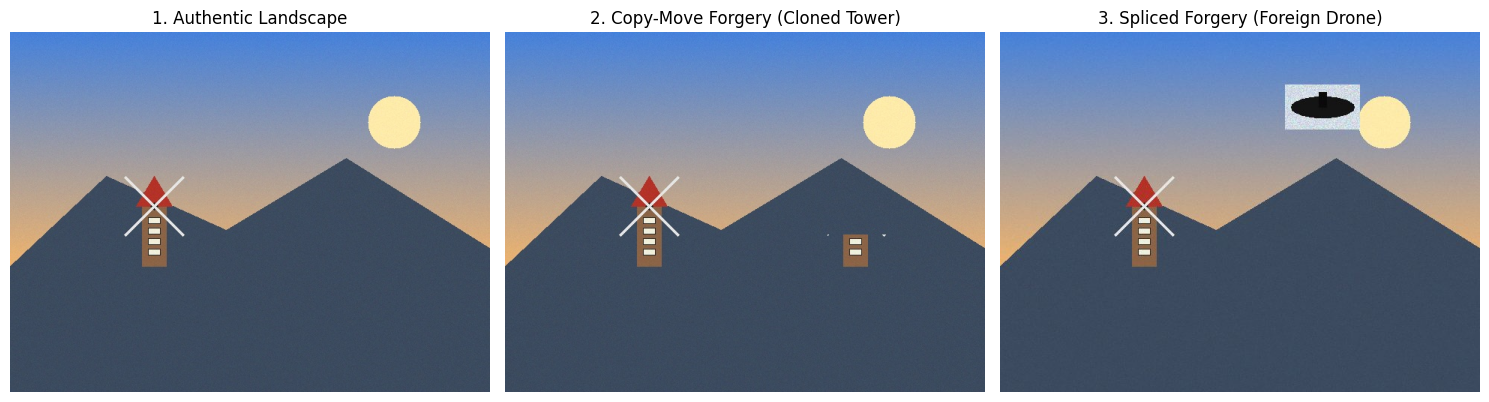

In [2]:
# Load authentic and tampered samples
auth_path = '../dataset/authentic/authentic_landscape.jpg'
cm_path = '../dataset/tampered/copy_move/forgery_copy_move_tower.jpg'
splice_path = '../dataset/tampered/splicing/forgery_spliced_uav.jpg'

_, img_auth = load_image_rgb(auth_path)
_, img_cm = load_image_rgb(cm_path)
_, img_splice = load_image_rgb(splice_path)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_auth); axes[0].set_title("1. Authentic Landscape"); axes[0].axis('off')
axes[1].imshow(img_cm); axes[1].set_title("2. Copy-Move Forgery (Cloned Tower)"); axes[1].axis('off')
axes[2].imshow(img_splice); axes[2].set_title("3. Spliced Forgery (Foreign Drone)"); axes[2].axis('off')
plt.tight_layout()
plt.show()

## 3. Technique 1: Error Level Analysis (ELA)
### Theory
When a JPEG image is re-compressed at a known quality level (e.g. 90%), unaltered regions show uniform error levels because they have reached compression equilibrium. Spliced or modified areas exhibit abnormal error spikes because they have undergone different quantization cycles.

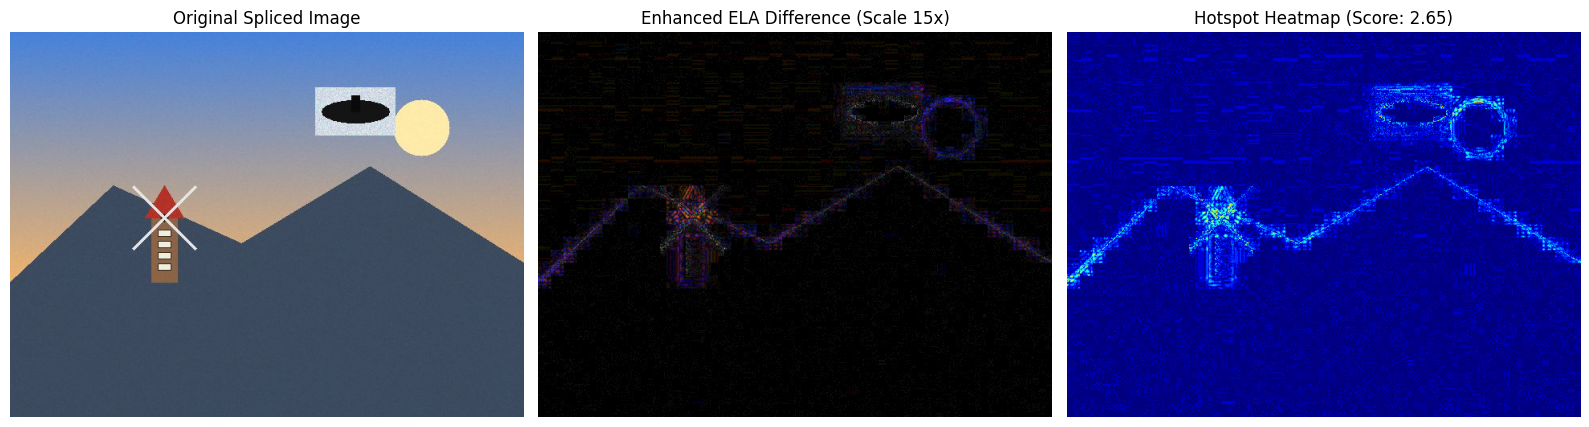

Mean Error: 0.29
Standard Deviation: 0.69
High Error Pixel Ratio: 0.0%


In [3]:
# Perform ELA on the spliced image
ela_result = perform_ela(img_splice, quality=90, scale_factor=15)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(img_splice)
axes[0].set_title("Original Spliced Image")
axes[0].axis('off')

axes[1].imshow(ela_result['ela_image_np'])
axes[1].set_title(f"Enhanced ELA Difference (Scale 15x)")
axes[1].axis('off')

axes[2].imshow(ela_result['heatmap_rgb'])
axes[2].set_title(f"Hotspot Heatmap (Score: {ela_result['ela_tampering_score']})")
axes[2].axis('off')

plt.tight_layout()
plt.show()

print(f"Mean Error: {ela_result['mean_error']}")
print(f"Standard Deviation: {ela_result['std_error']}")
print(f"High Error Pixel Ratio: {ela_result['high_error_ratio']}%")

## 4. Technique 2: Copy-Move Forgery Detection (ORB Features)
### Theory
ORB (Oriented FAST and Rotated BRIEF) identifies distinctive corner keypoints and extracts binary descriptors. We perform self-matching using k-NN with k=4, eliminate self-matches, filter pairs by minimum spatial Euclidean distance, and cluster displacement vectors (dx, dy).

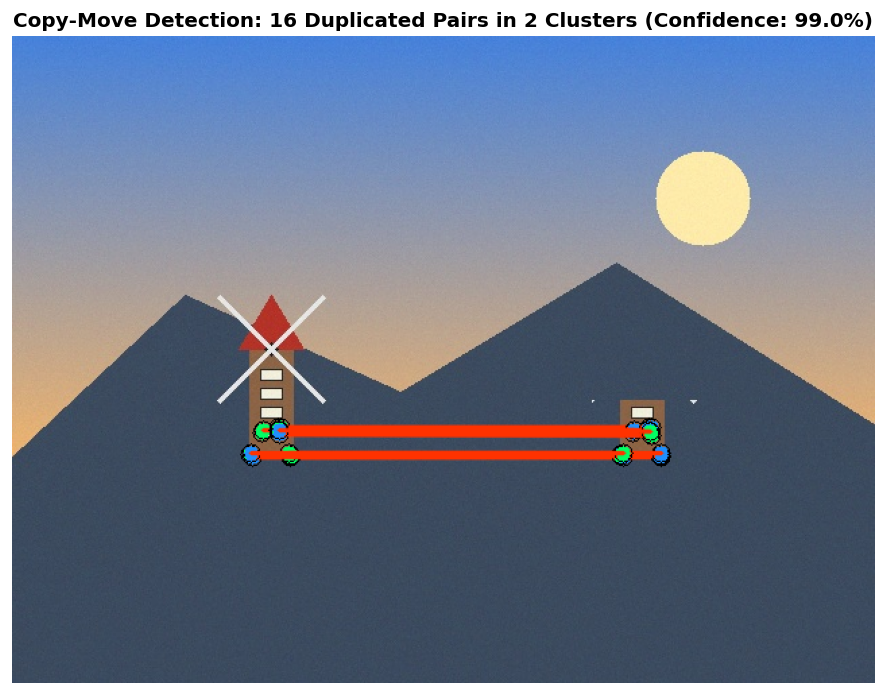

Keypoints Found: 442
Verified Duplicate Pairs: 16
Clusters: 2
Verdict: TAMPERED


In [4]:
# Detect Copy-Move Forgery
cm_result = detect_copy_move(img_cm, max_features=3000, min_distance=35)

plt.figure(figsize=(10, 7), dpi=120)
plt.imshow(cm_result['annotated_image'])
plt.title(f"Copy-Move Detection: {cm_result['match_count']} Duplicated Pairs in {cm_result['clusters']} Clusters (Confidence: {cm_result['confidence']}%)",
          fontweight='bold', fontsize=12)
plt.axis('off')
plt.show()

print(f"Keypoints Found: {cm_result['keypoints_found']}")
print(f"Verified Duplicate Pairs: {cm_result['match_count']}")
print(f"Clusters: {cm_result['clusters']}")
print(f"Verdict: {'TAMPERED' if cm_result['is_tampered'] else 'AUTHENTIC'}")

## 5. Technique 3: Noise Inconsistency & Splicing Detection
### Theory
Every camera sensor imparts unique noise (PRNU). By extracting high-frequency noise residuals via non-linear median filtering and mapping local block variance, we expose foreign spliced objects exhibiting anomalous noise variance ratios (P95 / Median).

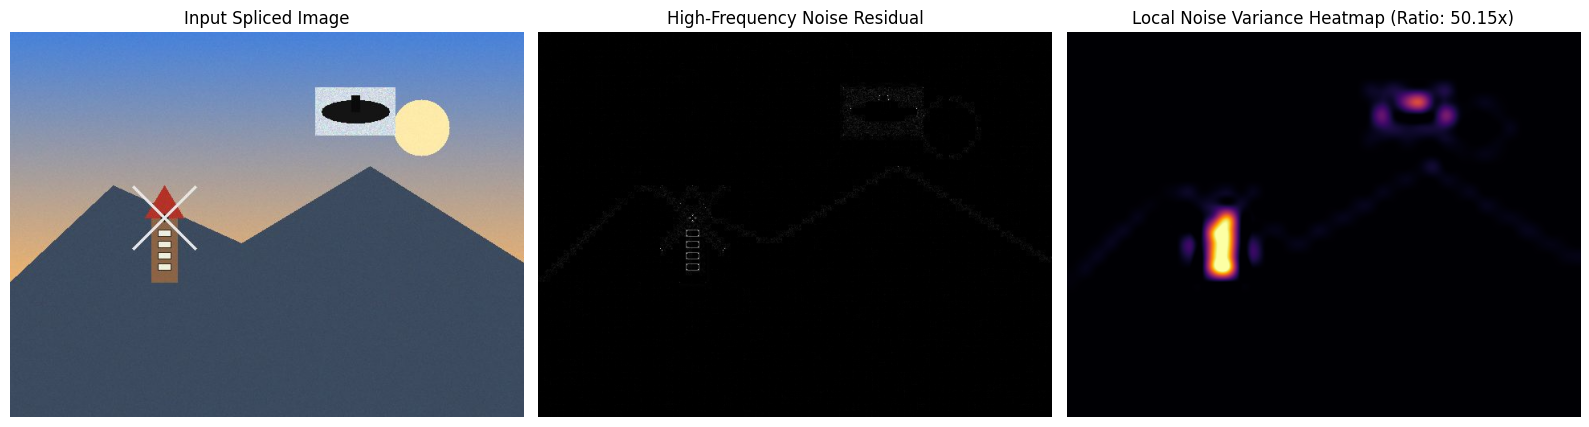

Variance Discrepancy Ratio (P95/Median): 50.15x
Noise Inconsistency Score: 99.0 / 100
Splicing Detected: True


In [5]:
# Detect Splicing via Noise Residual Analysis
splice_result = detect_splicing_noise(img_splice, block_size=16)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(img_splice)
axes[0].set_title("Input Spliced Image")
axes[0].axis('off')

axes[1].imshow(splice_result['noise_residual_rgb'])
axes[1].set_title("High-Frequency Noise Residual")
axes[1].axis('off')

axes[2].imshow(splice_result['variance_heatmap_rgb'])
axes[2].set_title(f"Local Noise Variance Heatmap (Ratio: {splice_result['variance_ratio']}x)")
axes[2].axis('off')

plt.tight_layout()
plt.show()

print(f"Variance Discrepancy Ratio (P95/Median): {splice_result['variance_ratio']}x")
print(f"Noise Inconsistency Score: {splice_result['noise_inconsistency_score']} / 100")
print(f"Splicing Detected: {splice_result['is_splicing_detected']}")

## 6. End-to-End Forensic Decision Fusion
Combines the findings of all forensic modules into an overall tampering risk verdict and confidence score.

In [6]:
# Multi-Modal Decision Fusion
meta_info = extract_metadata(cm_path)
final_verdict = calculate_overall_verdict(
    ela_score=ela_result['ela_tampering_score'],
    copy_move_matches=cm_result['match_count'],
    noise_score=splice_result['noise_inconsistency_score'],
    exif_suspicious=meta_info['is_suspicious']
)

print("=" * 60)
print("               FORENSIC DECISION SUMMARY                ")
print("=" * 60)
print(f" Verdict           : {final_verdict['verdict']}")
print(f" Risk Level        : {final_verdict['risk_level']}")
print(f" Forensic Risk Score: {final_verdict['forensic_risk_score']}%")
print(f" Primary Indicator : {final_verdict['primary_technique']}")
print("=" * 60)

               FORENSIC DECISION SUMMARY                
 Verdict           : HIGH FORENSIC RISK / POTENTIAL TAMPERING
 Risk Level        : HIGH
 Forensic Risk Score: 99.0%
 Primary Indicator : Copy-Move Cloned Duplication


## 7. Performance Evaluation Benchmark
Calculate Accuracy, Precision, Recall, Specificity, and F1-Score across the benchmark dataset.

      IMAGE FORENSIC ANALYZER - PERFORMANCE EVALUATION BENCHMARK      

Total Test Images Evaluated: 6
---------------------------------------------------------------------------
Filename                         | Actual     | Confidence | Result  
---------------------------------------------------------------------------
authentic_landscape.jpg          | AUTHENTIC  | 25.0%      | [PASS]  
authentic_lake.jpg               | AUTHENTIC  | 9.8%       | [PASS]  
forgery_copy_move_tower.jpg      | TAMPERED   | 98.0%      | [PASS]  
forgery_copy_move_boat.jpg       | TAMPERED   | 98.0%      | [PASS]  
forgery_spliced_uav.jpg          | TAMPERED   | 99.0%      | [PASS]  
forgery_spliced_balloon.jpg      | TAMPERED   | 99.0%      | [PASS]  
---------------------------------------------------------------------------

         PERFORMANCE METRICS SUMMARY         
 True Positives  (TP) : 4
 True Negatives  (TN) : 2
 False Positives (FP) : 0
 False Negatives (FN) : 0
----------------------------

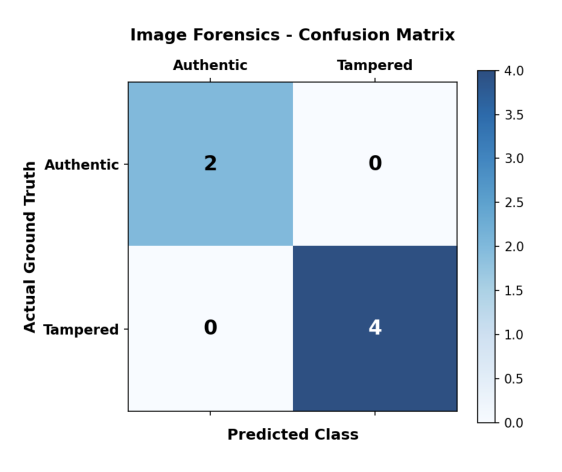

In [7]:
from evaluate import evaluate_dataset

# Run evaluation on dataset
metrics = evaluate_dataset(dataset_dir='../dataset', save_matrix_path='../reports/confusion_matrix.png')

# Display confusion matrix
if os.path.exists('../reports/confusion_matrix.png'):
    cm_img = Image.open('../reports/confusion_matrix.png')
    plt.figure(figsize=(7, 6))
    plt.imshow(cm_img)
    plt.axis('off')
    plt.show()